Step 1: Load Data & Descriptive Statistics

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
# Set style for cleaner plots
sns.set_theme(style="whitegrid")

In [6]:
# 1. Load the dataset
df = pd.read_csv("cleaned_titanic.csv")

In [8]:
# 2. Check structure & data types
print(df.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 775 entries, 0 to 774
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     775 non-null    int64  
 1   pclass       775 non-null    int64  
 2   sex          775 non-null    object 
 3   age          775 non-null    float64
 4   sibsp        775 non-null    int64  
 5   parch        775 non-null    int64  
 6   fare         775 non-null    float64
 7   embarked     775 non-null    object 
 8   class        775 non-null    object 
 9   who          775 non-null    object 
 10  adult_male   775 non-null    bool   
 11  embark_town  773 non-null    object 
 12  alive        775 non-null    object 
 13  alone        775 non-null    bool   
dtypes: bool(2), float64(2), int64(4), object(6)
memory usage: 74.3+ KB
None


In [9]:
print("\nFirst 5 rows:")
display(df.head())


First 5 rows:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,Southampton,no,True


In [10]:
# 3. Descriptive statistics
print("\nNumerical Summary:")
display(df.describe())


Numerical Summary:


,survived,pclass,age,sibsp,parch,fare
count,775.000000,775.000000,775.000000,775.000000,775.000000,775.000000
mean,0.412903,2.246452,29.581187,0.529032,0.420645,34.878403
std,0.492674,0.853574,13.766359,0.990326,0.840565,52.408474
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,1.000000,21.000000,0.000000,0.000000,8.050000
50%,0.000000,3.000000,28.000000,0.000000,0.000000,15.900000
75%,1.000000,3.000000,36.000000,1.000000,1.000000,34.197900
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [11]:
print("\nCategorical Summary:")
display(df.describe(include=['O']))


Categorical Summary:


,sex,embarked,class,who,embark_town,alive
count,775,775,775,775,773,775
unique,2,3,3,3,3,2
top,male,S,Third,man,Southampton,no
freq,483,562,401,443,560,455


Step 2: Correlation Matrix

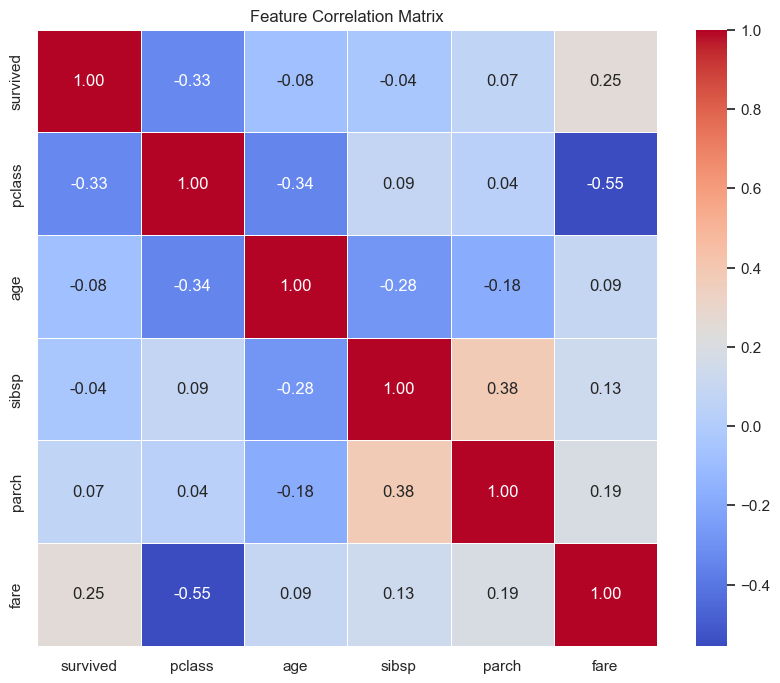

In [12]:
# Correlation matrix for numerical features
plt.figure(figsize=(10, 8))
numeric_df = df.select_dtypes(include=[np.number])
corr = numeric_df.corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Feature Correlation Matrix")
plt.show()

Step 3: Create 4–5 Meaningful Visualizations

In [16]:
print(df.columns)

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'embark_town', 'alive',
       'alone'],
      dtype='object')


1.Survival Rate by Class (Bar Plot):

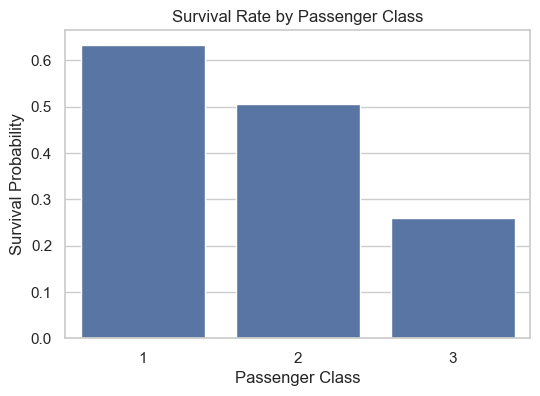

In [17]:
plt.figure(figsize=(6, 4))
sns.barplot(x='pclass', y='survived', data=df, errorbar=None)
plt.title("Survival Rate by Passenger Class")
plt.ylabel("Survival Probability")
plt.xlabel("Passenger Class")
plt.show()

2.Survival Count by Gender

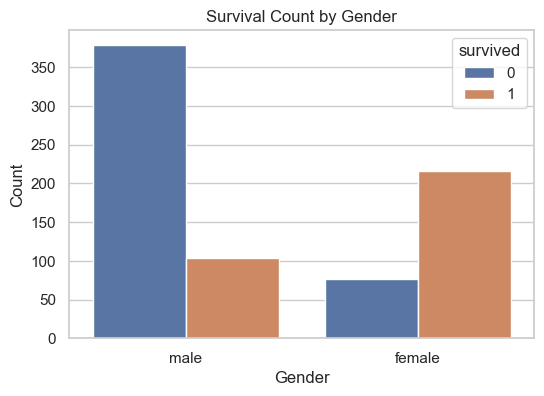

In [19]:
plt.figure(figsize=(6, 4))
sns.countplot(x='sex', hue='survived', data=df)
plt.title("Survival Count by Gender")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.show()

3.Age Distribution by Survival

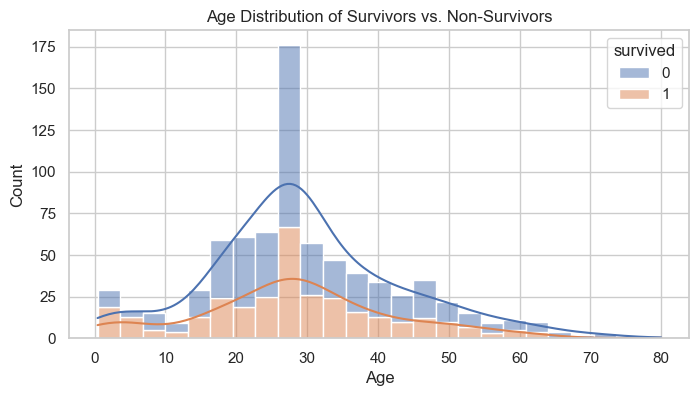

In [20]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x='age', hue='survived', multiple='stack', kde=True)
plt.title("Age Distribution of Survivors vs. Non-Survivors")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

4.Fare vs. Class Outliers (Box Plot).

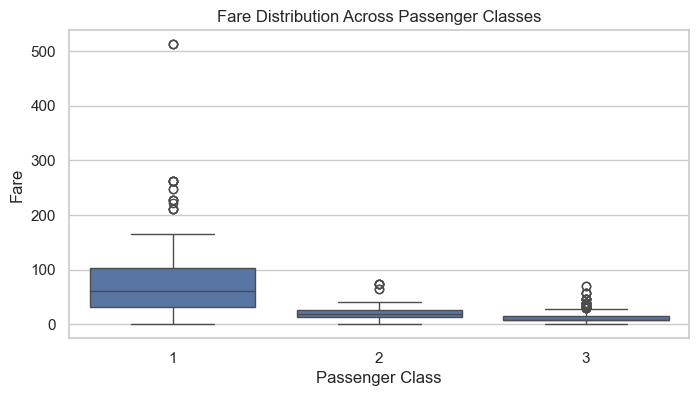

In [21]:
plt.figure(figsize=(8, 4))
sns.boxplot(x='pclass', y='fare', data=df)
plt.title("Fare Distribution Across Passenger Classes")
plt.xlabel("Passenger Class")
plt.ylabel("Fare")
plt.show()

Step 4: 5 Data Insights for Titanic

1.Gender Disparity: Women had a drastically higher survival rate than men, reflecting the "women and children first" evacuation protocol.

2.Class Privilege: Passengers in 1st Class (Pclass = 1) had significantly higher survival probabilities compared to 3rd Class passengers.

3.Fare Impact: Higher ticket fares correlate positively with survival, heavily overlapping with passenger class wealth dynamics.

4.Age Vulnerability: Children (younger age brackets) experienced higher survival rates compared to middle-aged adults.

5.Data Skewness: Ticket fares are heavily right-skewed, meaning a small percentage of passengers paid extremely high luxury fares.